# Random Forest Regressor - Dự đoán giá RAM DDR5 (USD/GB)

Dự án dự đoán giá RAM DDR5 (USD/GB) từ 3 nguồn dữ liệu CSV sử dụng mô hình **Random Forest Regressor**.

**Luồng xử lý:**
1. Đọc & gộp 3 file CSV
2. Trích đặc trưng từ tên sản phẩm (Regex)
3. Khám phá dữ liệu (EDA)
4. Train/Test split theo nhóm (tránh data leakage)
5. Pipeline tiền xử lý + Random Forest
6. Tinh chỉnh siêu tham số (RandomizedSearchCV)
7. Trực quan hóa kết quả & Feature Importance
8. Lưu mô hình & dự đoán mẫu

## Cell 1 — Thư viện và cấu hình

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Trong Jupyter thì %matplotlib inline cho phép hiện biểu đồ trực tiếp
%matplotlib inline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
try:
    _HERE = Path(__file__).resolve().parent  # chạy bằng file .py
except NameError:
    _HERE = Path.cwd()  # chạy trong notebook / cell tương tác

# Thư mục dataset/ cùng cấp với notebook
DATA_DIR = Path(os.environ.get("DATA_DIR", _HERE / "dataset"))
RESULTS_DIR = _HERE / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("✅ Sẵn sàng! Thư mục dữ liệu:", DATA_DIR)

FILE_A = DATA_DIR / "ram-price-observations.csv"
FILE_B = DATA_DIR / "ram_pricing_intelligence_2026.csv"
FILE_C = DATA_DIR / "costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv"

# Kiểm tra file tồn tại trước khi đọc
for f in [FILE_A, FILE_B, FILE_C]:
    if not f.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {f}\nHãy đặt các file CSV vào thư mục: {DATA_DIR}")
print("✅ Tất cả file CSV đã sẵn sàng.")

✅ Sẵn sàng! Thư mục dữ liệu: /home/claude/nb/dataset
✅ Tất cả file CSV đã sẵn sàng.


## Cell 2 — Đọc 3 file CSV

In [2]:
a = pd.read_csv(FILE_A)
b = pd.read_csv(FILE_B)
c = pd.read_csv(FILE_C)

print("A (bán lẻ Newegg/BestBuy):", a.shape)
print("B (eBay, nhiều loại RAM): ", b.shape)
print("C (costinflation DDR5):   ", c.shape)

print("\n--- Mẫu file A ---")
display(a.head(3))

A (bán lẻ Newegg/BestBuy): (414, 9)
B (eBay, nhiều loại RAM):  (2899, 17)
C (costinflation DDR5):    (19705, 16)

--- Mẫu file A ---


,capture_date_utc,product_id,product_label,kit_capacity_gb,title,seller,price_usd,usd_per_gb,verification_status
0,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
1,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
2,2026-08-12,corsair-vengeance-6000c30,Corsair Vengeance 32GB (2x16GB) DDR5-6000 CL30,32,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,Central Computers,529.99,16.562,discovery_only


## Cell 3 — Gộp 3 file về schema chung

Cột chung: `source`, `title`, `capacity_gb`, `price`, `usd_per_gb`, `condition`, `speed_hint`

In [3]:
df_a = pd.DataFrame({
    "source": "A_retail",
    "title": a["title"],
    "capacity_gb": a["kit_capacity_gb"],
    "price": a["price_usd"],
    "usd_per_gb": a["usd_per_gb"],
    "condition": "New",
    "speed_hint": np.nan,
})

b5 = b[(b["ram_generation"] == "DDR5") & (b["is_bulk_server"] == 0) & (b["unit_type"] != "Bulk")].copy()
b5 = b5.dropna(subset=["capacity_gb", "price"])
df_b = pd.DataFrame({
    "source": "B_ebay",
    "title": b5["title"],
    "capacity_gb": b5["capacity_gb"],
    "price": b5["price"],
    "usd_per_gb": b5["price"] / b5["capacity_gb"],
    "condition": b5["condition"],
    "speed_hint": b5["bus_speed_mhz"],
})

c = c[(c["quantity_value"] > 0) & c["normalized_price_amount"].notna()]
df_c = pd.DataFrame({
    "source": "C_costinflation",
    "title": c["product_name"],
    "capacity_gb": c["quantity_value"],
    "price": c["price_amount"],
    "usd_per_gb": c["normalized_price_amount"],
    "condition": "New",
    "speed_hint": np.nan,
})

df = pd.concat([df_a, df_b, df_c], ignore_index=True)
print("Sau khi gộp:", df.shape)
print(df["source"].value_counts())
display(df.head())

Sau khi gộp: (21473, 7)
source
C_costinflation    19704
B_ebay              1355
A_retail             414
Name: count, dtype: int64


,source,title,capacity_gb,price,usd_per_gb,condition,speed_hint
0,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
1,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
2,A_retail,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,32.0,529.99,16.562,New,NaN
3,A_retail,CORSAIR - Vengeance 32GB (2 x 16GB) 288-Pin PC...,32.0,539.99,16.875,New,NaN
4,A_retail,CORSAIR Vengeance 32GB (2 x 16GB) 288-Pin PC R...,32.0,539.99,16.875,New,NaN


## Cell 4 — Feature Engineering: Trích đặc trưng từ tên sản phẩm

Dùng **Regex** để đọc thông tin từ chuỗi tên sản phẩm:
- `brand` → hãng sản xuất
- `speed_mhz` → tốc độ bus (MHz)
- `cas_latency` → độ trễ CAS (CL)
- `num_sticks` → số thanh RAM trong kit
- `is_sodimm` → có phải RAM laptop?
- `has_rgb` → có đèn RGB?
- `is_ecc_server` → có phải RAM máy chủ?

In [4]:
BRANDS = ["Corsair", "G.Skill", "Kingston", "Crucial", "Micron", "TEAMGROUP", "T-Force", "Patriot",
          "Samsung", "SK hynix", "A-Tech", "Acer", "Biwin", "ADATA", "XPG", "Lexar", "PNY",
          "OLOy", "Mushkin", "Silicon Power", "Netac", "Thermaltake", "Gigabyte", "ASUS", "MSI"]


def find_brand(t):
    t = str(t).lower().replace(" ", "").replace("-", "").replace(".", "")
    for br in BRANDS:
        if br.lower().replace(" ", "").replace("-", "").replace(".", "") in t:
            return br
    if "hynix" in t:
        return "SK hynix"
    if "gskill" in t or "tridentz" in t:
        return "G.Skill"
    return "Other"


def find_speed(row):
    if pd.notna(row["speed_hint"]):
        return row["speed_hint"]
    t = str(row["title"])
    m = re.search(r"\b([3-9]\d{3})\s*(?:MHz|MT/s|MTs)?\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"B(\d{4})C\d{2}", t)  # kiểu mã Corsair: ...B6000C30
    return float(m.group(1)) if m else np.nan


def find_cl(t):
    t = str(t)
    m = re.search(r"\bCL\s?-?(\d{2})\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"\b(\d{2})-\d{2}-\d{2}-\d{2,3}\b", t)
    if m:
        return float(m.group(1))
    m = re.search(r"B\d{4}C(\d{2})", t)
    return float(m.group(1)) if m else np.nan


def find_sticks(t):
    m = re.search(r"\(?\b(\d)\s*[xX]\s*\d+\s*GB", str(t))
    return int(m.group(1)) if m else 1


df["brand"]        = df["title"].apply(find_brand)
df["speed_mhz"]    = df.apply(find_speed, axis=1)
df["cas_latency"]  = df["title"].apply(find_cl)
df["num_sticks"]   = df["title"].apply(find_sticks)
df["is_sodimm"]    = df["title"].str.contains(r"SO-?DIMM|laptop|notebook", case=False, regex=True).astype(int)
df["has_rgb"]      = df["title"].str.contains("RGB", case=False).astype(int)
df["is_ecc_server"]= df["title"].str.contains(r"ECC|RDIMM|registered|server", case=False, regex=True).astype(int)

# Loại điều kiện hiếm và giá bất thường (outlier)
df = df[~df["condition"].isin(["For parts or not working"])]
q_low, q_high = df["usd_per_gb"].quantile([0.005, 0.995])
df = df[df["usd_per_gb"].between(q_low, q_high)].reset_index(drop=True)

print("✅ Sau khi làm sạch:", df.shape)
display(df[["source", "brand", "capacity_gb", "speed_mhz", "cas_latency", "num_sticks", "usd_per_gb"]].head())

✅ Sau khi làm sạch: (21268, 14)


,source,brand,capacity_gb,speed_mhz,cas_latency,num_sticks,usd_per_gb
0,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
1,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
2,A_retail,Corsair,32.0,6000.0,30.0,2,16.562
3,A_retail,Corsair,32.0,6000.0,30.0,2,16.875
4,A_retail,Corsair,32.0,6000.0,NaN,2,16.875


## Cell 5 — EDA: Khám phá dữ liệu

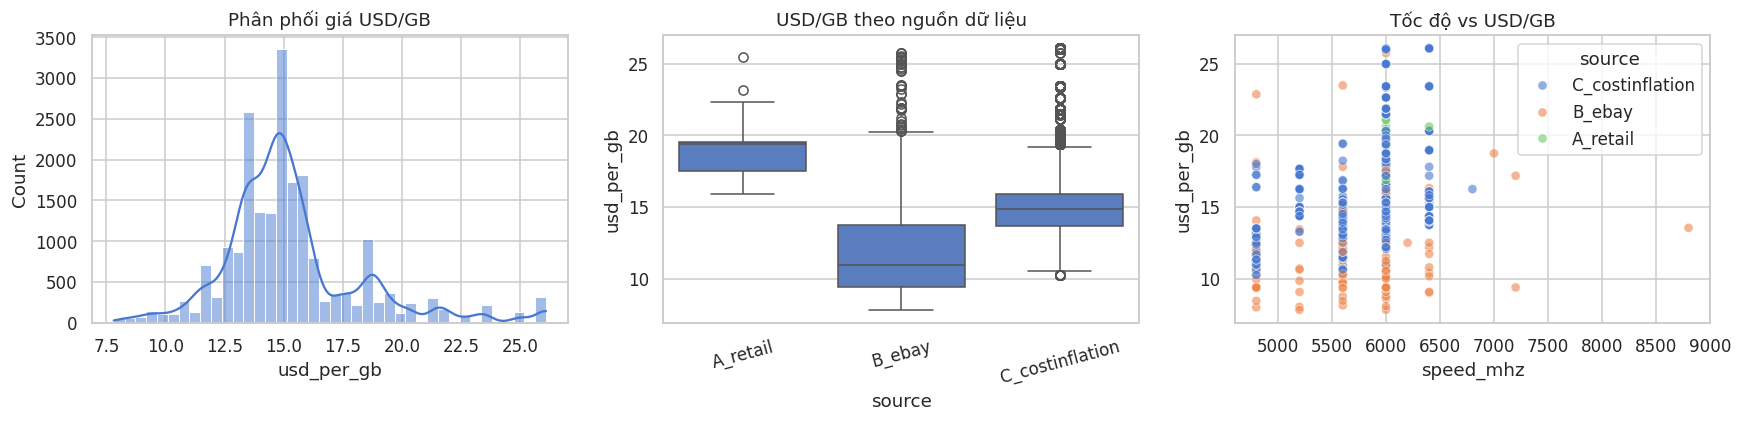


📊 Giá trị bị thiếu:
speed_hint     20163
speed_mhz        106
cas_latency     2156
dtype: int64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["usd_per_gb"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Phân phối giá USD/GB")

sns.boxplot(data=df, x="source", y="usd_per_gb", ax=axes[1])
axes[1].set_title("USD/GB theo nguồn dữ liệu")
axes[1].tick_params(axis="x", rotation=15)

sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=RANDOM_STATE),
                x="speed_mhz", y="usd_per_gb", hue="source", ax=axes[2], alpha=0.6)
axes[2].set_title("Tốc độ vs USD/GB")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_eda.png", dpi=110)
plt.show()

print("\n📊 Giá trị bị thiếu:")
missing = df.isna().sum()
print(missing[missing > 0])

## Cell 6 — Chia Train / Test (GroupShuffleSplit)

> ⚠️ Dùng **GroupShuffleSplit** để đảm bảo cùng một sản phẩm không xuất hiện ở cả train lẫn test — tránh **data leakage**.

In [6]:
TARGET   = "usd_per_gb"
NUM_COLS = ["capacity_gb", "speed_mhz", "cas_latency", "num_sticks", "is_sodimm", "has_rgb", "is_ecc_server"]
CAT_COLS = ["brand", "source", "condition"]

X = df[NUM_COLS + CAT_COLS]
y = df[TARGET]
groups = df["title"].str.lower().str.replace(r"\s+", " ", regex=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test   = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test   = y.iloc[train_idx], y.iloc[test_idx]
groups_train      = groups.iloc[train_idx]

print(f"✅ Train: {len(X_train)} dòng | Test: {len(X_test)} dòng")

✅ Train: 16518 dòng | Test: 4750 dòng


## Cell 7 — Pipeline tiền xử lý + Random Forest cơ bản

Pipeline gồm 2 bước:
1. **Tiền xử lý**: điền NaN bằng median, One-Hot Encode cột chữ
2. **Mô hình**: `RandomForestRegressor` với 300 cây

In [7]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])

rf_base = Pipeline([
    ("prep", preprocess),
    ("rf", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_base.fit(X_train, y_train)


def evaluate(model, name):
    pred = model.predict(X_test)
    mae  = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2   = r2_score(y_test, pred)
    print(f"[{name}]  MAE = {mae:.3f} USD/GB | RMSE = {rmse:.3f} | R² = {r2:.3f}")
    return pred


pred_base    = evaluate(rf_base, "RF mặc định")
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"[Baseline đoán trung bình]  MAE = {baseline_mae:.3f} USD/GB")

[RF mặc định]  MAE = 1.374 USD/GB | RMSE = 1.956 | R² = 0.499
[Baseline đoán trung bình]  MAE = 1.927 USD/GB


## Cell 8 — Tinh chỉnh siêu tham số (RandomizedSearchCV + GroupKFold)

Thử **15 tổ hợp tham số** ngẫu nhiên × **3-fold CV** = 45 lần fit.

> ⏳ Cell này mất khoảng 1–3 phút tùy máy.

In [8]:
param_dist = {
    "rf__n_estimators":    [200, 300, 500],
    "rf__max_depth":       [None, 10, 20, 30],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf":  [1, 2, 4],
    "rf__max_features":    ["sqrt", 0.5, 1.0],
}

search = RandomizedSearchCV(
    rf_base, param_dist, n_iter=15, cv=GroupKFold(n_splits=3),
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train, groups=groups_train)

print("\n🏆 Tham số tốt nhất:", search.best_params_)
print(f"📉 CV MAE tốt nhất: {-search.best_score_:.3f}")

rf_best   = search.best_estimator_
pred_best = evaluate(rf_best, "RF đã tinh chỉnh")

Fitting 3 folds for each of 15 candidates, totalling 45 fits



🏆 Tham số tốt nhất: {'rf__n_estimators': 300, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 2, 'rf__max_features': 0.5, 'rf__max_depth': 10}
📉 CV MAE tốt nhất: 1.154
[RF đã tinh chỉnh]  MAE = 1.169 USD/GB | RMSE = 1.919 | R² = 0.517


## Cell 9 — Trực quan hóa kết quả

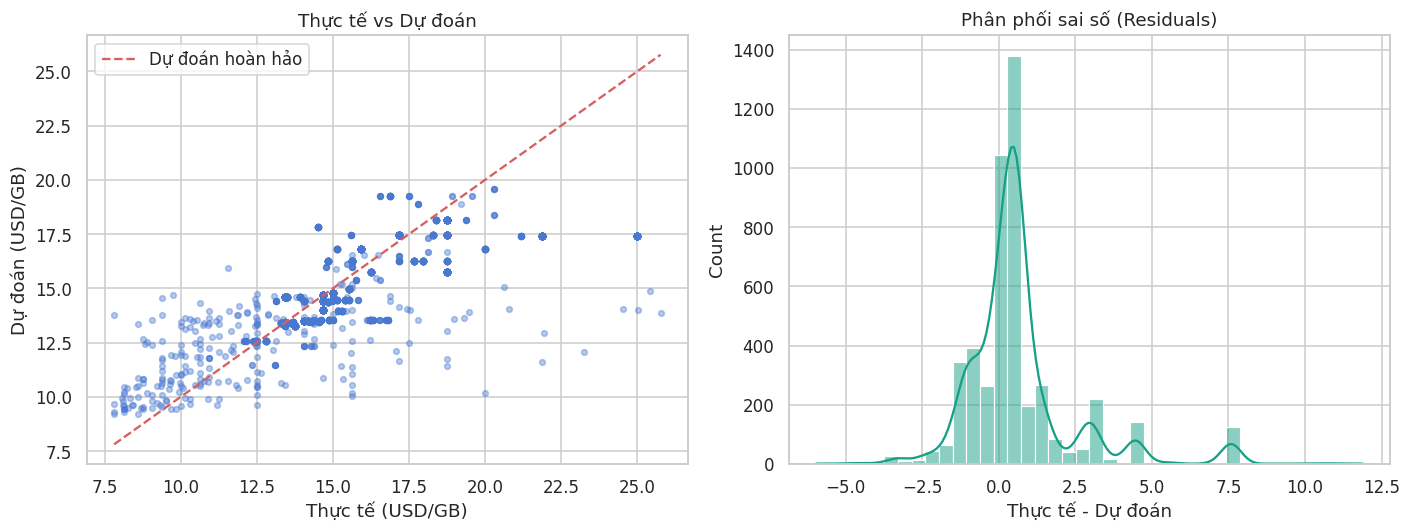

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ Actual vs Predicted
axes[0].scatter(y_test, pred_best, alpha=0.4, s=14)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="Dự đoán hoàn hảo")
axes[0].set_xlabel("Thực tế (USD/GB)")
axes[0].set_ylabel("Dự đoán (USD/GB)")
axes[0].set_title("Thực tế vs Dự đoán")
axes[0].legend()

# Biểu đồ phân phối sai số
residuals = y_test - pred_best
sns.histplot(residuals, bins=40, kde=True, ax=axes[1], color="#16a085")
axes[1].set_title("Phân phối sai số (Residuals)")
axes[1].set_xlabel("Thực tế - Dự đoán")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_actual_vs_pred.png", dpi=110)
plt.show()

## Cell 10 — Feature Importance & Permutation Importance

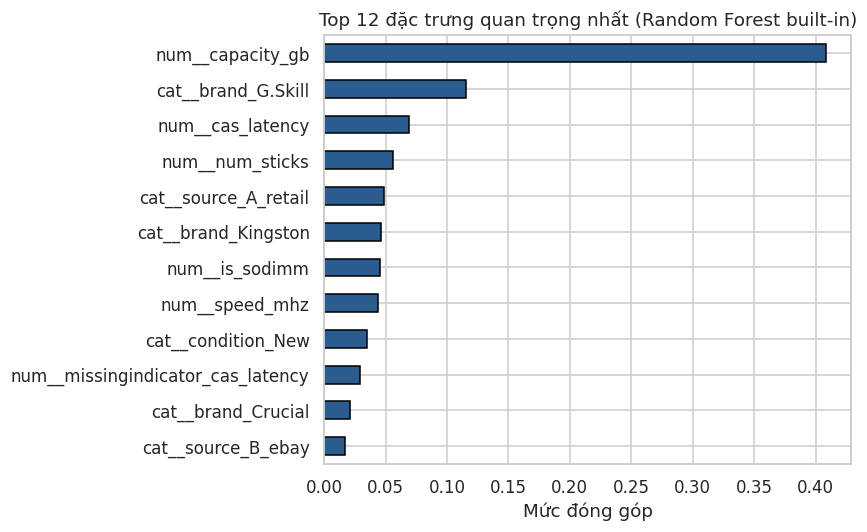

In [10]:
# Feature Importance built-in
feat_names = rf_best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_best.named_steps["rf"].feature_importances_, index=feat_names)
imp.sort_values().tail(12).plot(kind="barh", figsize=(8, 5), color="#2b5c8f", edgecolor="black")
plt.title("Top 12 đặc trưng quan trọng nhất (Random Forest built-in)")
plt.xlabel("Mức đóng góp")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_feature_importance.png", dpi=110)
plt.show()

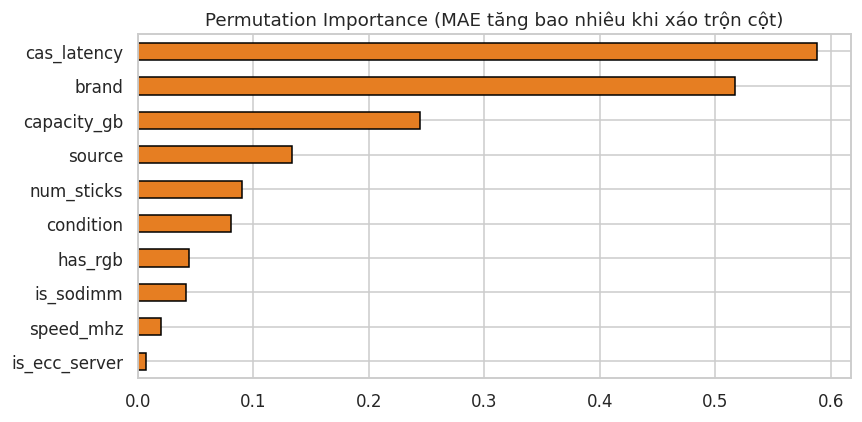

In [11]:
# Permutation Importance (đáng tin cậy hơn — đo trực tiếp trên tập test)
perm = permutation_importance(
    rf_best, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error"
)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_s.plot(kind="barh", figsize=(8, 4), color="#e67e22", edgecolor="black")
plt.title("Permutation Importance (MAE tăng bao nhiêu khi xáo trộn cột)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_permutation_importance.png", dpi=110)
plt.show()

## Cell 11 — Lưu mô hình & Dự đoán mẫu

In [12]:
# Lưu mô hình
model_path = RESULTS_DIR / "rf_ram_price.joblib"
joblib.dump(rf_best, model_path)
print(f"💾 Mô hình đã lưu: {model_path}")

# Dự đoán một sản phẩm mẫu
sample = pd.DataFrame([{
    "capacity_gb": 32, "speed_mhz": 6000, "cas_latency": 30, "num_sticks": 2,
    "is_sodimm": 0, "has_rgb": 1, "is_ecc_server": 0,
    "brand": "Corsair", "source": "A_retail", "condition": "New",
}])
pred_sample = rf_best.predict(sample)[0]
print(f"\n🎯 Dự đoán: {pred_sample:.2f} USD/GB")
print(f"   → Kit 32GB ≈ {pred_sample * 32:.0f} USD")

💾 Mô hình đã lưu: /home/claude/nb/results/rf_ram_price.joblib

🎯 Dự đoán: 19.44 USD/GB
   → Kit 32GB ≈ 622 USD


## Cell 12 — Tải lại mô hình và dự đoán tùy chỉnh

Thay đổi các giá trị trong `my_ram` để dự đoán RAM bất kỳ:

In [13]:
# Tải lại mô hình đã lưu (có thể dùng ở file khác)
model = joblib.load(RESULTS_DIR / "rf_ram_price.joblib")

# ✏️ Thay đổi thông số RAM muốn dự đoán tại đây:
my_ram = pd.DataFrame([{
    "capacity_gb":  64,          # Dung lượng tổng (GB)
    "speed_mhz":    5600,        # Tốc độ bus (MHz)
    "cas_latency":  36,          # CAS Latency
    "num_sticks":   2,           # Số thanh
    "is_sodimm":    0,           # 1 nếu là RAM laptop
    "has_rgb":      0,           # 1 nếu có đèn RGB
    "is_ecc_server": 0,         # 1 nếu là RAM máy chủ ECC
    "brand":        "G.Skill",  # Hãng sản xuất
    "source":       "A_retail", # Nguồn dữ liệu
    "condition":    "New",      # Tình trạng
}])

result = model.predict(my_ram)[0]
cap    = my_ram["capacity_gb"].iloc[0]
print(f"🎯 Dự đoán: {result:.2f} USD/GB")
print(f"   → Kit {cap:.0f}GB ≈ {result * cap:.0f} USD")

🎯 Dự đoán: 18.29 USD/GB
   → Kit 64GB ≈ 1171 USD
